# Loop calling on chromatin tracing data

This tutorial calls chromatin loops from DNA FISH traces with
`uchrom.strc.loop.call_loops_axiswise_f` (also `uc.tl.call_loops`),
U-Chrom's GPU-capable implementation of the axis-wise F-test of ArcFISH
(Yu et al. 2025, bioRxiv 10.1101/2025.11.26.690837), which gives the
authors' test statistics and loops (uchrom-reproducibility `supp_table3/arcfish_parity`).  You will
call loops on one chromosome and on all of them at once, compare the calls
with the paper and its tutorial (`match_loops`), check them against the
population distance and contact maps (`uchrom.fea`, `uchrom.pl.draw_loops`),
tune `LoopCallerParams`, and keep the calls in `cd.intervals` /
`cd.results` and on disk.  Data: Takei et al. 2021 (*Nature* 590:344) DNA
seqFISH+ in mouse ES cells at 25 kb — 20 regions of 60 loci (1.5–2.4 Mb),
one per chromosome, 8,285 traces in 201 cells.  `ds.load("takei2021_mesc")`
gives them as a `ChromData`; the first call downloads the FOF-CT core table
`4DNFIHF3JCBY` (22 MB) and its cell and RNA tables once from 4DN and builds
the dataset in the data directory (replicate 2 of the experiment,
`4DNFIQXONUUH`, 34 MB, is fetched for the comparison with the paper).
Runtime: about a minute.

**How the caller works** (per chromosome):

1. **Per-axis variance** — for each locus pair `(i, j)` and each axis, a
   robust (median-based) variance of `x[j] - x[i]` across traces.  Modelling
   the axes separately absorbs the anisotropic localisation error of FISH
   (z is usually noisier).
2. **Filter + normalise** — LOWESS on log genomic distance flags per-trace
   outliers (4 σ) and divides out the distance decay.
3. **Per-axis F-test** — a candidate pair (100 kb–1 Mb apart) is compared
   with its local background, the pairs within 50 kb of both of its loci
   but not within 25 kb of both; a loop has *lower* variance than its
   background.
4. **Cauchy combination** of the three per-axis p-values, weighted by the
   inverse of each axis's typical per-locus variance (its noise).
5. **BH-FDR**, clustering of accepted pairs within 50 kb, and the
   lowest-p **summit** of each cluster.
6. **Contact filter** — a summit is kept when more than 1/2 (a cluster of
   two pairs) or 1/3 (any other cluster) of the traces bring its loci
   closer than the mean distance of loci 25 kb apart; summits with
   p < `pval_cutoff` are the loops.

In [1]:
import shutil
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from chromdata import ChromData
import uchrom as uc
import uchrom.datasets as ds

plt.rcParams["figure.dpi"] = 90

OUT = Path("_out"); OUT.mkdir(exist_ok=True)   # outputs: tutorials/_out/ (ignored by git)

## Load the Takei 2021 traces

`ds.load` returns the dataset as a `ChromData`: the loci are `cd.bins`,
every detected spot a row of `cd.spots` (built from the 4DN FISH Omics
Format table, with the cell table in `cd.cells`).

In [2]:
cd = ds.load("takei2021_mesc")
print(cd)
per_chrom = pd.DataFrame({
    "loci": cd.bins.groupby("chrom", observed=True).size(),
    "traces": cd.spots.groupby("chrom", observed=True)["trace_id"].nunique(),
})
per_chrom.T

ChromData: n_spots=316995, n_traces=8285, n_cells=201, n_bins=1200
  spots:   ['chrom', 'start', 'end', 'trace_id', 'spot_id', 'cell_id', 'extra_cell_roi_id', 'bin_id']
  cells:   ['extra_cell_roi_id', 'keep1', 'centroid_x', 'centroid_y', 'nucleus_area_um2', 'cytoplasm_area_um2', 'rna.Eef2', 'rna.Auts2', 'rna.Bdnf', 'rna.Clu', 'rna.Cx3cr1', 'rna.Efna5', 'rna.Npy', 'rna.S100b', 'rna.Slc17a7', 'rna.Stmn2', 'rna.Zfp42', 'rna.Myc', 'rna.Ccnd2', 'rna.Mcm2', 'rna.Mki67', 'rna.Sox2', 'rna.Nes', 'rna.Cdk1', 'rna.Mtf2', 'rna.Jade1', 'rna.Cenpa', 'rna.Aurka', 'rna.Plk1', 'rna.Mdm2', 'rna.Aebp2', 'rna.Tet1', 'rna.Nodal', 'rna.Tfcp2l1', 'rna.Tdh', 'rna.Sall4', 'rna.Nanog', 'rna.Esrrb', 'rna.Pou5f1', 'rna.Klf6', 'rna.Ctgf', 'rna.Peg10', 'rna.Myh9', 'rna.Tbx3', 'rna.Otx2', 'rna.Dnmt3a', 'rna.Dnmt3b', 'rna.Lin28a', 'rna.Lin28b', 'rna.Zscan4c', 'rna.Zfp352'] (201 cells)
  points:  {'rna': 3335}
  uns:     ['fofct_header', 'xyz_unit', 'genome_assembly', 'fofct_companions', 'cell_spatial', 'dataset']


chrom,chr1,chr10,chr11,chr12,chr13,chr14,chr15,chr16,chr17,chr18,chr19,chr2,chr3,chr4,chr5,chr6,chr7,chr8,chr9,chrX
loci,60,60,60,60,60,60,60,60,60,60,60,60,60,60,60,60,60,60,60,60
traces,424,418,442,424,430,416,400,421,427,445,460,418,408,423,406,415,430,438,423,217


## Call loops on one chromosome

`chrom="chr6"` restricts the call to one chromosome.  The defaults are
ArcFISH's (`fdr_cutoff=0.1`, `pval_cutoff=1e-5`, candidates 100 kb–1 Mb
apart, background 25–50 kb, clustering gap 50 kb, contact cutoff from loci
25 kb apart); `device="auto"` picks CUDA, then Apple MPS, then the CPU.

In [3]:
from uchrom.strc.loop import call_loops_axiswise_f, LoopCallerParams

COLS = ["chrom1", "start1", "end1", "start2", "end2", "stat", "pval", "fdr", "cluster_size", "contact_freq"]
loops6 = call_loops_axiswise_f(cd, chrom="chr6", verbose=True)
loops6[COLS]

[loop/chr6] variance cube...


[loop/chr6] 1360 pairs tested, 7 candidates, 2 loops


,chrom1,start1,end1,start2,end2,stat,pval,fdr,cluster_size,contact_freq
0,chr6,50300000,50325000,50525000,50550000,6.349792e+05,5.012918e-07,0.000341,2,0.540230
1,chr6,50675000,50700000,50800000,50825000,1.479049e+07,2.152125e-08,0.000029,2,0.717557


The table is BEDPE-like (one row per loop summit): `stat` is the combined
Cauchy statistic, `score` = -log10 `pval`, `cluster_size` the number of
candidate pairs in the summit's cluster and `summit_i`, `summit_j` its loci
(indices within the chromosome).  It is stored, with its provenance, under
the default key `"loops.axiswise_f"`: as a typed `pair` interval table in
`cd.intervals` and as a record in `cd.results`.

In [4]:
print(cd.intervals)
rec = cd.results.record("loops.axiswise_f")
print(rec.function, "| kind:", rec.kind)
print("params:", rec.params)

IntervalStore({'loops.axiswise_f': <pair, 2 rows>})
uchrom.strc.loop.call_loops_axiswise_f | kind: intervals
params: {'cut_lo': 100000.0, 'cut_up': 1000000.0, 'inner_cut': 25000.0, 'outer_cut': 50000.0, 'fdr_cutoff': 0.1, 'pval_cutoff': 1e-05, 'gap': 50000.0, 'contact_sep': 25000.0, 'k_sigma': 4.0, 'frac': 0.1, 'min_cluster_size': 1}


ArcFISH's own tutorial runs `LoopCaller(fdr_cutoff=0.1)` on this chromosome
(on both replicates of the experiment; this tutorial reads replicate 1) and
reports two loops.  `match_loops` tells which of them this call finds (both
loci within one 25-kb bin).

In [5]:
from uchrom.strc.loop import match_loops

# ArcFISH documentation, tutorial "Loop and domain calling" (Takei 2021 25-kb data, chr6)
arcfish_chr6 = pd.DataFrame({"start1": [50_300_000, 50_675_000], "start2": [50_525_000, 50_800_000]})
arcfish_chr6.assign(called_here=match_loops(arcfish_chr6, loops6, tol=25_000))

,start1,start2,called_here
0,50300000,50525000,True
1,50675000,50800000,True


## Check the call against the population maps

A loop is a pair of loci that are closer than their genomic separation
predicts, i.e. a dot off the diagonal of the median distance map and of the
contact-frequency map.  `uchrom.fea.distance_map` gives the exact median
over traces (in memory or streaming over a backed store);
`contact_frequency` counts the traces in which a pair is closer than a
cutoff — here the median distance of adjacent loci, the same kind of
cutoff the caller's contact filter uses.  `uchrom.pl.draw_loops` circles
the calls on any map whose rows are the loci in `dm.bins`.

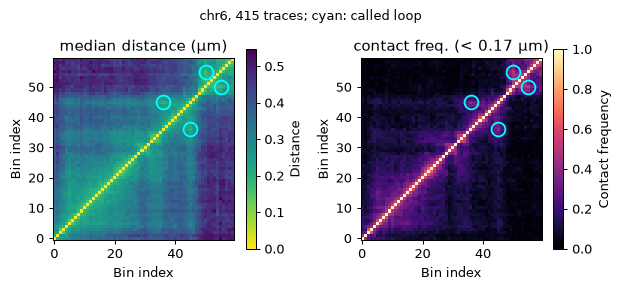

In [6]:
from uchrom.fea import contact_frequency, distance_map
from uchrom.pl import draw_loops, plot_contact_map, plot_distance_matrix

dm = distance_map(cd, "chr6")                               # median over traces, µm
cutoff = float(np.nanmedian(np.diag(dm.matrix, 1)))
cf, _, _ = contact_frequency(cd, threshold=cutoff, chrom="chr6")

fig, axes = plt.subplots(1, 2, figsize=(7, 3.1))
plot_distance_matrix(dm.matrix, title=f"median distance (µm)", ax=axes[0])
plot_contact_map(cf, title=f"contact freq. (< {cutoff:.2f} µm)", ax=axes[1])
fig.suptitle(f"chr6, {dm.n_traces} traces; cyan: called loop", fontsize=10)
for ax in axes:
    draw_loops(ax, loops6, dm.bins, ms=11)
plt.tight_layout(); plt.show()

## All chromosomes at once

With `chrom=None` (the default) the caller runs every chromosome and merges
the per-chromosome tables into one table under one key — here through the
flat alias `uc.tl.call_loops`, which forwards to the same function.

In [7]:
t0 = time.perf_counter()
loops = uc.tl.call_loops(cd)
print(f"{len(loops)} loops on {loops.chrom1.nunique()} of {cd.bins.chrom.nunique()} chromosomes "
      f"({time.perf_counter() - t0:.1f} s)")
loops[COLS]

10 loops on 5 of 20 chromosomes (9.0 s)


,chrom1,start1,end1,start2,end2,stat,pval,fdr,cluster_size,contact_freq
0,chr13,21900000,21925000,22000000,22025000,2.120440e+06,1.501150e-07,0.000056,5,0.615385
1,chr13,22050000,22075000,22275000,22300000,1.785973e+06,1.782277e-07,0.000056,5,0.380682
2,chr13,23275000,23300000,23375000,23400000,3.235601e+05,9.837737e-07,0.000131,3,0.580786
3,chr13,23300000,23325000,23500000,23525000,2.173865e+05,1.464258e-06,0.000153,4,0.354067
4,chr13,23400000,23425000,23500000,23525000,3.034500e+05,1.048970e-06,0.000131,4,0.541850
5,chr16,91075000,91100000,91350000,91375000,1.530145e+05,2.080259e-06,0.002925,2,0.523810
6,chr2,109900000,109925000,110200000,110225000,2.906032e+06,1.095342e-07,0.000151,3,0.497076
7,chr6,50300000,50325000,50525000,50550000,6.349792e+05,5.012918e-07,0.000341,2,0.540230
8,chr6,50675000,50700000,50800000,50825000,1.479049e+07,2.152125e-08,0.000029,2,0.717557
9,chrX,76825457,76850457,76925457,76950457,8.588285e+05,3.706327e-07,0.000471,1,0.692982


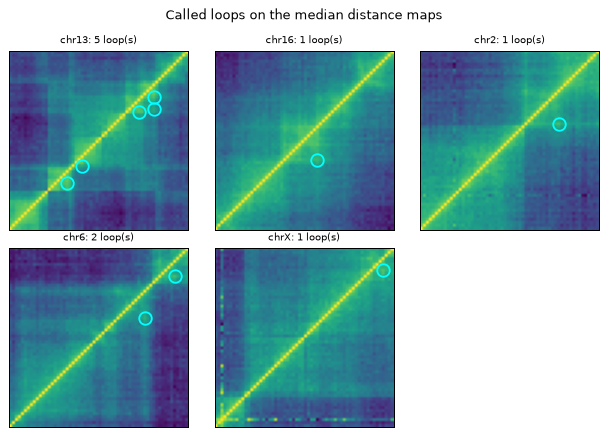

In [8]:
chroms = list(dict.fromkeys(loops.chrom1))                # the chromosomes with loops
fig, axes = plt.subplots(int(np.ceil(len(chroms) / 3)), 3, figsize=(7, 2.45 * np.ceil(len(chroms) / 3)),
                         squeeze=False)
for ax, chrom in zip(axes.flat, chroms):
    d = distance_map(cd, chrom)
    ax.imshow(d.matrix, cmap="viridis_r", origin="lower")
    draw_loops(ax, loops, d.bins, symmetric=False)            # the loops on this chromosome
    ax.set_title(f"{chrom}: {(loops.chrom1 == chrom).sum()} loop(s)", fontsize=8)
    ax.set_xticks([]); ax.set_yticks([])
for ax in axes.flat[len(chroms):]:
    ax.axis("off")
fig.suptitle("Called loops on the median distance maps", fontsize=10)
plt.tight_layout()
plt.show()

**How this compares with the paper.**  On this dataset the ArcFISH preprint
reports 25 loops, 17 of them supported by Hi-C / PLAC-seq / ChIA-PET loop
lists (SnapFISH: 41 loops, 23 supported) — from both replicates of the
experiment; replicate 1 alone, as above, gives ten.  Replicate 2 is the 4DN
FOF-CT core table `4DNFIQXONUUH` (`ds.fetch("takei_rep2")`); call on both
replicates together:

In [9]:
rep2 = ChromData.from_fofct(ds.fetch("takei_rep2"))   # replicate 2: the 4DN FOF-CT core table, fetched once

def loci_and_traces(c, rep):                           # trace ids made unique per replicate
    sp = c.spots_with_loci()[["chrom", "start", "end"]]
    return sp.assign(trace_id=rep + "_" + c.spots["trace_id"].astype(str).to_numpy())

both = ChromData(coords=np.vstack([np.asarray(cd.coords), np.asarray(rep2.coords)]),
                 spots=pd.concat([loci_and_traces(cd, "rep1"), loci_and_traces(rep2, "rep2")], ignore_index=True))
loops_both = uc.tl.call_loops(both, key_added=None)
print(f"both replicates: {both.n_traces} traces, {len(loops_both)} loops on {loops_both.chrom1.nunique()} chromosomes")
arcfish_chr6.assign(called_on_both=match_loops(arcfish_chr6, loops_both[loops_both.chrom1 == "chr6"], tol=25_000))

both replicates: 18383 traces, 25 loops on 11 chromosomes


,start1,start2,called_on_both
0,50300000,50525000,True
1,50675000,50800000,True


The paper's 25 loops with the default thresholds, the two of ArcFISH's chr6
tutorial among them: the caller gives the authors' calls
(uchrom-reproducibility `supp_table3/arcfish_parity`), and with the traces of one replicate the test
has less power.  The next section shows how the call set of replicate 1
grows when the thresholds are relaxed.

## Tuning the thresholds

Every knob lives on `LoopCallerParams`.  `key_added=None` returns the table
without storing it, so the default call above stays in `cd.intervals`.

In [10]:
settings = {
    "default (fdr 0.1, p 1e-5)": LoopCallerParams(),
    "p 1e-3": LoopCallerParams(pval_cutoff=1e-3),
    "fdr 0.2, p 1e-3": LoopCallerParams(fdr_cutoff=0.2, pval_cutoff=1e-3),
}
counts = {name: (loops if name.startswith("default") else
                 uc.tl.call_loops(cd, params=p, key_added=None)).groupby("chrom1").size()
          for name, p in settings.items()}
table = pd.DataFrame(counts).fillna(0).astype(int)
table.loc["total"] = table.sum()
table.T

chrom1,chr1,chr10,chr13,chr15,chr16,chr2,chr3,chr4,chr5,chr6,chr7,chr8,chr9,chrX,total
"default (fdr 0.1, p 1e-5)",0,0,5,0,1,1,0,0,0,2,0,0,0,1,10
p 1e-3,1,2,6,2,1,2,4,2,0,3,1,0,0,1,25
"fdr 0.2, p 1e-3",0,3,5,4,2,3,2,3,2,3,1,1,1,1,31


The thresholds act on the test matrices, which `arcfish_loop_matrices`
returns for one chromosome (as ArcFISH's `LoopCaller.call_loops`): per locus
pair the statistic, p-value and FDR, and the masks of the candidates (FDR),
the cluster summits that pass the contact filter and the loops (`final`):

{'tested pairs': 1360, 'candidate': 7, 'summit': 3, 'final': 2}


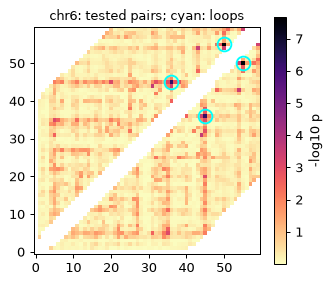

In [11]:
from uchrom.strc.loop.axiswise_f import arcfish_loop_matrices

m = arcfish_loop_matrices(cd, chrom="chr6")                  # the test matrices of one chromosome; not stored
upper = np.triu(np.ones_like(m["pval"], dtype=bool), 1)
print({"tested pairs": int(np.isfinite(m["pval"][upper]).sum()),
       **{k: int(m[k][upper].sum()) for k in ("candidate", "summit", "final")}})

fig, ax = plt.subplots(figsize=(3.8, 3.3))
im = ax.imshow(-np.log10(m["pval"]), cmap="magma_r", origin="lower")
plt.colorbar(im, ax=ax, label="-log10 p")
draw_loops(ax, loops6, dm.bins, ms=11)
ax.set_title("chr6: tested pairs; cyan: loops", fontsize=10)
plt.tight_layout(); plt.show()

## `copy=True`: leave the input untouched

By default the caller writes into `cd` and returns the table.  With
`copy=True` it returns a new `ChromData` that holds the result instead.

In [12]:
cd_chr2 = uc.tl.call_loops(cd, chrom="chr2", key_added="loops.chr2", copy=True)
print(type(cd_chr2).__name__, "intervals:", list(cd_chr2.intervals))
print("'loops.chr2' in the original:", "loops.chr2" in cd.intervals)

ChromData intervals: ['loops.axiswise_f', 'loops.chr2']
'loops.chr2' in the original: False


## Save and reload

Interval tables and result records travel with the `.chromdata.zarr`
store; a backed read loads them eagerly while the coordinates stay on disk.
For other tools, export BEDPE.

In [13]:
path = OUT / "takei2021_loops.chromdata.zarr"
if path.exists():
    shutil.rmtree(path)
cd.write(path)

back = ChromData.read(path, backed=True)
print(back.intervals)
print(back.results.record("loops.axiswise_f").created_utc)

bedpe = OUT / "takei2021_loops.bedpe"
back.intervals["loops.axiswise_f"][["chrom1", "start1", "end1", "chrom2", "start2", "end2", "score"]] \
    .to_csv(bedpe, sep="\t", header=False, index=False)
print("wrote", bedpe)

IntervalStore({'loops.axiswise_f': <pair, 10 rows>})
2026-10-14T06:23:53+00:00
wrote _out/takei2021_loops.bedpe


## Command line

The same caller runs from the shell on a store or a FOF-CT table, writing
BEDPE, CSV or an updated store:

```bash
python -m uchrom.strc.loop --input=data.chromdata.zarr --output=chr6_loops.bedpe --chrom=chr6
```

## Notes

- U-Chrom's own implementation of the published algorithm (4 σ filter,
  LOWESS normalisation, per-axis F-test, Cauchy combination, BH-FDR,
  summit and contact-frequency rules); uchrom-reproducibility `supp_table3/arcfish_parity` checks
  it against the authors' package: the same test matrices and loops on
  five datasets.
- On Apple MPS the variance cube is computed in float32 (CUDA / CPU use
  float64), which can move borderline candidates across the thresholds.
- On a backed store the caller streams over the traces (`streaming=True`,
  memory `O(n_bins²)`); the `tad_calling` tutorial shows it.

## Next steps

- `tad_calling` — ArcFISH TADs, streaming on a backed store, and projecting
  TADs / loops onto bins and spots with `uchrom.strc.enrichment`.
- `fishnet_domains` — single-allele domains with FISHnet.
- `compartment` — A/B compartments, validated against Hi-C.